# 🏙️ Tipologia Socioeconômica dos Municípios Brasileiros (Sem Grandes Metrópoles)
## Análise Multidimensional de Agrupamento: Diagnóstico de K Ideal, Simulação de 30 Rodadas e Visualizações Comparativas

### 🎯 Objetivos Centrais desta Análise:
1. **Isolamento Metropolitano:** Separação das **53 grandes metrópoles e capitais** (população $\ge 500.000$ habitantes ou capitais de estado) em planilha dedicada (`metropoles_brasileiras.xlsx`), evitando que megalópoles como São Paulo, Rio e capitais distorçam a escala e a variância dos agrupamentos.
2. **Análise dos 5.518 Municípios Pequenos e Médios:** Aplicação do algoritmo de K-Means sobre o universo das cidades do interior brasileiro.
3. **Determinação do K Ideal:** Aplicação do **Método do Cotovelo (Inércia / WCSS)** e do **Coeficiente de Silhueta (Silhouette Score)** para $K \in [2, 10]$.
4. **Avaliação da Variável de Porte:** Comparar a estrutura dos clusters **COM o tamanho do município** (`log_populacao`) vs. **SEM o tamanho** (apenas intensidades relativas por 100 hab e percentuais).
5. **Simulação de 30 Execuções (Estabilidade):** Rodar o K-Means 30 vezes com sementes aleatórias distintas para checar a recorrência e robustez dos padrões.
6. **Mapeamento Visual e Tabelas Puras:** Gráficos de dispersão, mapas de calor (*heatmaps* de z-scores) e tabelas descritivas sem rotulação prévia.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.spatial.distance import cdist

# Estilo editorial de visualização
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

print("✅ Ambiente configurado com scikit-learn, scipy, pandas, seaborn e matplotlib!")


✅ Ambiente configurado com scikit-learn, scipy, pandas, seaborn e matplotlib!


## 📂 1. Carregamento dos Dados, Isolamento das Metrópoles e Preparação das Matrizes
Carregamos as abas auditadas de `traducao_municipios_consolidado.xlsx`:
1. Identificamos as **53 metrópoles e capitais de estado** (cidades com população $\ge 500.000$ ou capitais).
2. Exportamos esses municípios para `dados_prioridades/metropoles_brasileiras.xlsx` e `.csv` para análise individual aprofundada posterior.
3. Preparamos as matrizes para os **5.518 municípios restantes**:
   * **Matriz A (COM Porte):** Inclui `log_populacao` junto com os indicadores per capita.
   * **Matriz B (SEM Porte):** Exclui qualquer variável de população absoluta, focando na intensidade socioeconômica pura.


In [2]:
EXCEL_PATH = 'traducao_municipios_consolidado.xlsx'

print(f"⏳ Carregando bases de dados municipais de {EXCEL_PATH}...")
df_trab = pd.read_excel(EXCEL_PATH, sheet_name='Trabalho_e_Renda')
df_prev = pd.read_excel(EXCEL_PATH, sheet_name='Previdencia_Economia')
df_educ = pd.read_excel(EXCEL_PATH, sheet_name='Educacao_Escolas')
df_saude = pd.read_excel(EXCEL_PATH, sheet_name='Saude_Medicamentos')

df_mun = df_trab[['cod_ibge7', 'cod_ibge6', 'municipio', 'uf', 'populacao_2025']].copy()
pop = df_mun['populacao_2025'].replace(0, np.nan)

# Códigos IBGE das 27 Capitais de Estado
cod_capitais = [
    1100205, 1200401, 1302603, 1400100, 1501402, 1600303, 1721000,
    2111300, 2211001, 2304400, 2408102, 2507507, 2611606, 2704302, 2800308, 2927408,
    3106200, 3205309, 3304557, 3550308,
    4106902, 4205407, 4314902,
    5002704, 5103403, 5208707, 5300108
]

# Critério de Metrópole: Capital de Estado OU População >= 500.000 habitantes
mask_metropoles = df_mun['cod_ibge7'].isin(cod_capitais) | (df_mun['populacao_2025'] >= 500000)

# Indicadores de Intensidade Socioeconômica (per capita / por 100 hab / taxas)
features_sem_porte = {
    'taxa_clt_100_hab': (df_trab['trabalhadores_clt_ativos'] / pop) * 100,
    'taxa_mei_100_hab': (df_trab['total_mei_ativos'] / pop) * 100,
    'servidores_100_hab': (df_trab['total_servidores_publicos'] / pop) * 100,
    'aposentados_100_hab': (df_prev['aposentadorias_rgps_dezembro'] / pop) * 100,
    'peso_prev_pib_pct': df_prev['aposentadorias_sobre_pib_pct'].fillna(0),
    'familias_bf_100_hab': (df_trab['familias_bolsa_familia'] / pop) * 100,
    'bpc_100_hab': (df_trab['beneficiarios_bpc_loas'] / pop) * 100,
    'pe_de_meia_cobertura_pct': (df_educ['qtd_beneficiarios_pe_de_meia'] / df_educ['mat_em_publico'].replace(0, np.nan) * 100).fillna(0).clip(upper=100),
    'dep_fundeb_uniao_pct': (df_educ['pct_uniao_rede_municipal'] * 100).fillna(0),
    'farmacia_pop_100_hab': (df_saude['fp_total'] / pop * 100).fillna(0)
}
df_feat_sem = pd.DataFrame(features_sem_porte).fillna(0)

# Indicadores com Porte Populacional Logarítmico
df_feat_com = df_feat_sem.copy()
df_feat_com['log_populacao'] = np.log10(df_mun['populacao_2025'].clip(lower=100))

# 1. Exportação das Metrópoles para Análise Separada
os.makedirs('dados_prioridades', exist_ok=True)
df_metropoles_resumo = pd.concat([df_mun[mask_metropoles], df_feat_com[mask_metropoles]], axis=1)
df_metropoles_resumo['criterio'] = np.where(df_mun.loc[mask_metropoles, 'cod_ibge7'].isin(cod_capitais) & (df_mun.loc[mask_metropoles, 'populacao_2025'] >= 500000), 'Capital e >=500k',
                                    np.where(df_mun.loc[mask_metropoles, 'cod_ibge7'].isin(cod_capitais), 'Capital (<500k)', 'Grande Centro (>=500k)'))

out_metr_xlsx = 'dados_prioridades/metropoles_brasileiras.xlsx'
with pd.ExcelWriter(out_metr_xlsx, engine='openpyxl') as writer:
    df_metropoles_resumo.sort_values(by='populacao_2025', ascending=False).to_excel(writer, sheet_name='Resumo_Metropoles', index=False)
    df_trab[mask_metropoles].sort_values(by='populacao_2025', ascending=False).to_excel(writer, sheet_name='Trabalho_e_Renda', index=False)
    df_prev[mask_metropoles].sort_values(by='populacao_2025', ascending=False).to_excel(writer, sheet_name='Previdencia_Economia', index=False)
    df_educ[mask_metropoles].sort_values(by='populacao_2025', ascending=False).to_excel(writer, sheet_name='Educacao_Escolas', index=False)
    df_saude[mask_metropoles].sort_values(by='populacao_2025', ascending=False).to_excel(writer, sheet_name='Saude_Medicamentos', index=False)

df_metropoles_resumo.to_csv('dados_prioridades/metropoles_brasileiras.csv', sep=';', index=False, encoding='utf-8')
print(f"🏛️ {mask_metropoles.sum()} Metrópoles salvas com sucesso em '{out_metr_xlsx}'!")

# 2. Base de Treinamento dos Clusters (Apenas os municípios restantes)
df_mun_treino = df_mun[~mask_metropoles].reset_index(drop=True)
df_feat_sem_treino = df_feat_sem[~mask_metropoles].reset_index(drop=True)
df_feat_com_treino = df_feat_com[~mask_metropoles].reset_index(drop=True)

# Padronização Z-Score (StandardScaler)
scaler_com = StandardScaler()
X_com = scaler_com.fit_transform(df_feat_com_treino)

scaler_sem = StandardScaler()
X_sem = scaler_sem.fit_transform(df_feat_sem_treino)

print(f"✅ Matrizes preparadas para o K-Means (SEM Metrópoles):")
print(f" - Cenário A (COM Tamanho): {X_com.shape[1]} variáveis padronizadas para {X_com.shape[0]} cidades.")
print(f" - Cenário B (SEM Tamanho): {X_sem.shape[1]} variáveis padronizadas para {X_sem.shape[0]} cidades.")


⏳ Carregando bases de dados municipais de traducao_municipios_consolidado.xlsx...


🏛️ 53 Metrópoles salvas com sucesso em 'dados_prioridades/metropoles_brasileiras.xlsx'!
✅ Matrizes preparadas para o K-Means (SEM Metrópoles):
 - Cenário A (COM Tamanho): 11 variáveis padronizadas para 5518 cidades.
 - Cenário B (SEM Tamanho): 10 variáveis padronizadas para 5518 cidades.


## 📐 2. Diagnóstico do K Ideal: Método do Cotovelo e Coeficiente de Silhueta
Testamos $K$ variando de **2 até 10 grupos** calculando:
1. **Inércia (WCSS - Within-Cluster Sum of Squares):** Mede a dispersão interna. O cotovelo aponta a estabilização do ganho explicativo.
2. **Coeficiente de Silhueta:** Varia de -1 a +1. Mede a separabilidade e coesão entre os grupos.


⏳ Executando diagnósticos de K=2 até K=10 para ambos os cenários (sem metrópoles)...


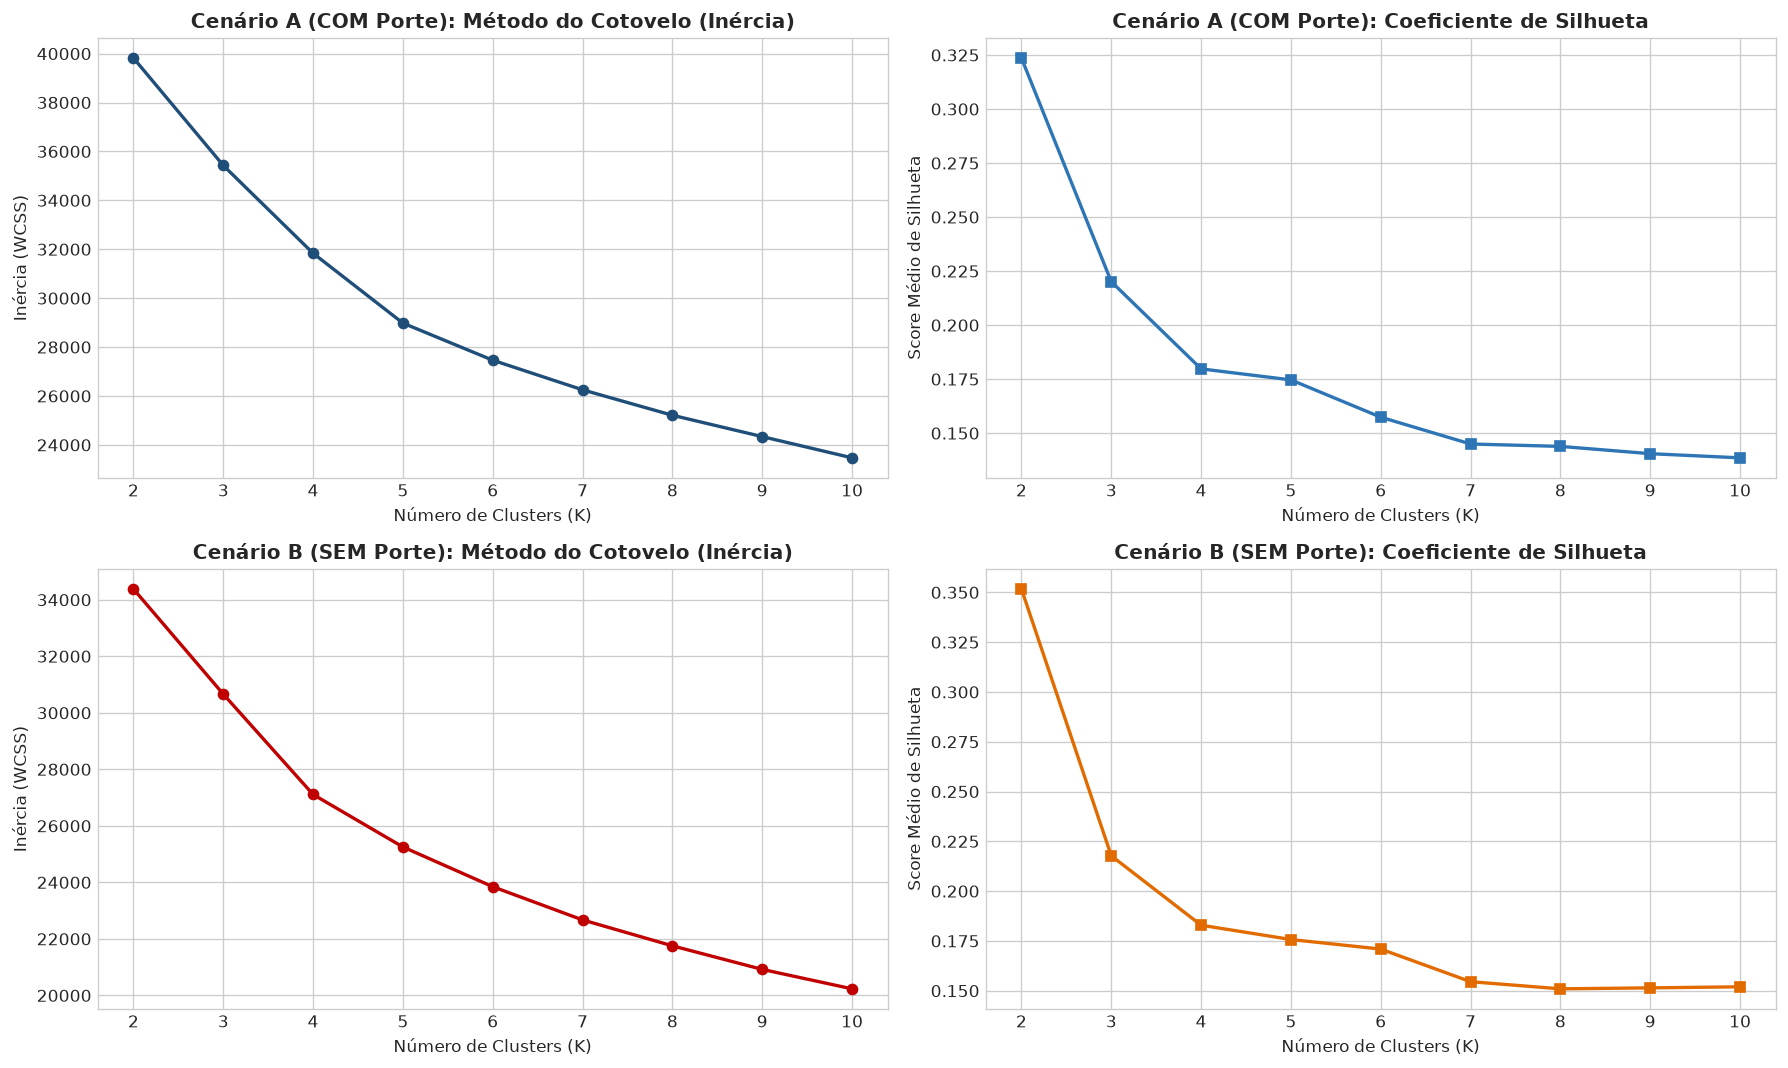

📊 Tabela Comparativa de Métricas por K (Base de 5.518 Cidades):


,K,Inercia_COM,Silhueta_COM,Inercia_SEM,Silhueta_SEM
0,2,39821.0,0.324,34380.4,0.352
1,3,35427.7,0.220,30661.4,0.218
2,4,31835.5,0.180,27109.1,0.183
3,5,28980.1,0.175,25252.1,0.176
4,6,27462.3,0.157,23845.9,0.171
5,7,26251.9,0.145,22670.7,0.155
6,8,25211.8,0.144,21754.1,0.151
7,9,24338.7,0.140,20919.9,0.151
8,10,23470.9,0.139,20232.5,0.152


In [3]:
k_range = range(2, 11)
diag_com = []
diag_sem = []

print("⏳ Executando diagnósticos de K=2 até K=10 para ambos os cenários (sem metrópoles)...")
for k in k_range:
    # Cenário A: Com Porte
    km_a = KMeans(n_clusters=k, random_state=42, n_init=10)
    lab_a = km_a.fit_predict(X_com)
    sil_a = silhouette_score(X_com, lab_a)
    diag_com.append({'K': k, 'Inercia': km_a.inertia_, 'Silhueta': sil_a})
    
    # Cenário B: Sem Porte
    km_b = KMeans(n_clusters=k, random_state=42, n_init=10)
    lab_b = km_b.fit_predict(X_sem)
    sil_b = silhouette_score(X_sem, lab_b)
    diag_sem.append({'K': k, 'Inercia': km_b.inertia_, 'Silhueta': sil_b})

df_diag_com = pd.DataFrame(diag_com)
df_diag_sem = pd.DataFrame(diag_sem)

# Gráficos Comparativos: Cotovelo e Silhueta
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# 1. Cotovelo Com Porte
axes[0, 0].plot(df_diag_com['K'], df_diag_com['Inercia'], marker='o', color='#1F4E79', lw=2)
axes[0, 0].set_title('Cenário A (COM Porte): Método do Cotovelo (Inércia)', fontweight='bold')
axes[0, 0].set_xlabel('Número de Clusters (K)')
axes[0, 0].set_ylabel('Inércia (WCSS)')

# 2. Silhueta Com Porte
axes[0, 1].plot(df_diag_com['K'], df_diag_com['Silhueta'], marker='s', color='#2E75B6', lw=2)
axes[0, 1].set_title('Cenário A (COM Porte): Coeficiente de Silhueta', fontweight='bold')
axes[0, 1].set_xlabel('Número de Clusters (K)')
axes[0, 1].set_ylabel('Score Médio de Silhueta')

# 3. Cotovelo Sem Porte
axes[1, 0].plot(df_diag_sem['K'], df_diag_sem['Inercia'], marker='o', color='#C00000', lw=2)
axes[1, 0].set_title('Cenário B (SEM Porte): Método do Cotovelo (Inércia)', fontweight='bold')
axes[1, 0].set_xlabel('Número de Clusters (K)')
axes[1, 0].set_ylabel('Inércia (WCSS)')

# 4. Silhueta Sem Porte
axes[1, 1].plot(df_diag_sem['K'], df_diag_sem['Silhueta'], marker='s', color='#E26B00', lw=2)
axes[1, 1].set_title('Cenário B (SEM Porte): Coeficiente de Silhueta', fontweight='bold')
axes[1, 1].set_xlabel('Número de Clusters (K)')
axes[1, 1].set_ylabel('Score Médio de Silhueta')

plt.tight_layout()
plt.show()

print("📊 Tabela Comparativa de Métricas por K (Base de 5.518 Cidades):")
tabela_diag = df_diag_com[['K']].copy()
tabela_diag['Inercia_COM'] = df_diag_com['Inercia'].round(1)
tabela_diag['Silhueta_COM'] = df_diag_com['Silhueta'].round(3)
tabela_diag['Inercia_SEM'] = df_diag_sem['Inercia'].round(1)
tabela_diag['Silhueta_SEM'] = df_diag_sem['Silhueta'].round(3)
display(tabela_diag)


## 🔁 3. Simulação de Estabilidade: Rodando o K-Means 30 Vezes
Para verificar se os agrupamentos são robustos contra variações aleatórias da inicialização, rodamos o algoritmo **30 vezes com sementes diferentes** ($seed \in [1, 30]$) para $K=6$.
Alinhamos os centróides entre as rodadas via distância euclidiana (`cdist`) e calculamos a média e o desvio padrão de cada dimensão.


In [4]:
def executar_simulacao_30x(X_matriz, df_orig, K=6, n_runs=30):
    # Execução base (seed=42)
    km_base = KMeans(n_clusters=K, random_state=42, n_init=10)
    labels_base = km_base.fit_predict(X_matriz)
    ref_centroids = km_base.cluster_centers_
    
    lista_centroides = [ref_centroids]
    
    for s in range(1, n_runs):
        km_iter = KMeans(n_clusters=K, random_state=s, n_init=5)
        km_iter.fit(X_matriz)
        cents = km_iter.cluster_centers_
        
        # Alinhamento pelo vizinho mais próximo com os centróides de referência
        dist_matrix = cdist(cents, ref_centroids)
        alinhado = np.zeros_like(ref_centroids)
        melhores = np.argmin(dist_matrix, axis=1)
        for idx_c, idx_ref in enumerate(melhores):
            alinhado[idx_ref] = cents[idx_c]
        lista_centroides.append(alinhado)
        
    tensor_cents = np.array(lista_centroides)
    
    # Médias das 30 rodadas em escala z-score
    cents_mean_scaled = tensor_cents.mean(axis=0)
    cents_std_scaled = tensor_cents.std(axis=0)
    
    return labels_base, cents_mean_scaled, cents_std_scaled

labels_com, mean_com_sc, std_com_sc = executar_simulacao_30x(X_com, df_feat_com_treino, K=6, n_runs=30)
labels_sem, mean_sem_sc, std_sem_sc = executar_simulacao_30x(X_sem, df_feat_sem_treino, K=6, n_runs=30)

print(f"✅ Simulação de 30 execuções concluída com sucesso para ambos os cenários (K=6)!")


✅ Simulação de 30 execuções concluída com sucesso para ambos os cenários (K=6)!


## 🔬 4. Características Puras dos Clusters: Cenário A (COM Tamanho da Cidade)
Abaixo estão as características médias reais nas 5.518 cidades resultantes das 30 execuções para os **6 clusters**, sem rotulação prévia.


In [5]:
df_com_analise = df_feat_com_treino.copy()
df_com_analise['cluster'] = labels_com
df_com_analise['populacao'] = df_mun_treino['populacao_2025']

caract_com = df_com_analise.groupby('cluster').agg({
    'populacao': ['count', 'mean', 'median'],
    'servidores_100_hab': 'mean',
    'taxa_clt_100_hab': 'mean',
    'taxa_mei_100_hab': 'mean',
    'aposentados_100_hab': 'mean',
    'peso_prev_pib_pct': 'mean',
    'familias_bf_100_hab': 'mean',
    'pe_de_meia_cobertura_pct': 'mean',
    'dep_fundeb_uniao_pct': 'mean',
    'farmacia_pop_100_hab': 'mean'
}).round(1)

print("📋 TABELA DE CARACTERÍSTICAS PURAS (COM TAMANHO DA CIDADE) — K=6:")
display(caract_com)


📋 TABELA DE CARACTERÍSTICAS PURAS (COM TAMANHO DA CIDADE) — K=6:


populacao                   servidores_100_hab taxa_clt_100_hab  \
            count     mean   median               mean             mean   
cluster                                                                   
0            1086  66836.5  34532.0                4.6             27.5   
1            1131   5831.6   4538.0                8.7             28.0   
2             616  24391.2  18924.5                6.6             15.4   
3            1100  10009.7   7620.0                6.2             28.5   
4             705   7255.4   5683.0                9.6             16.0   
5             880  40005.4  21276.5                6.0             16.0   

        taxa_mei_100_hab aposentados_100_hab peso_prev_pib_pct  \
                    mean                mean              mean   
cluster                                                          
0                    9.0                12.1               5.5   
1                    9.3                 8.0               4.2   
2                    5.8                17.4              19.0   
3                    9.5                19.9               9.8   
4                    6.2                 5.5               4.6   
5                    5.9                 8.0               6.6   

        familias_bf_100_hab pe_de_meia_cobertura_pct dep_fundeb_uniao_pct  \
                       mean                     mean                 mean   
cluster                                                                     
0                       5.6                     40.9                  2.8   
1                       5.6                     54.2                  3.1   
2                      13.0                     79.9                 42.6   
3                       5.0                     42.1                  3.2   
4                      12.5                     75.6                 24.7   
5                      12.7                     76.4                 39.0   

        farmacia_pop_100_hab  
                        mean  
cluster                       
0                        7.3  
1                        6.4  
2                        4.7  
3                       13.4  
4                        3.5  
5                        3.0

## 🔬 5. Características Puras dos Clusters: Cenário B (SEM Tamanho da Cidade / Intensidade Pura)
Neste cenário, **desprezamos a quantidade de habitantes**. Cidades médias e pequenas são agrupadas exclusivamente pelo seu perfil relativo (trabalho formal, previdência, assistência, funcionalismo).


In [6]:
df_sem_analise = df_feat_sem_treino.copy()
df_sem_analise['cluster'] = labels_sem
df_sem_analise['populacao'] = df_mun_treino['populacao_2025']

caract_sem = df_sem_analise.groupby('cluster').agg({
    'populacao': ['count', 'mean', 'median'],
    'servidores_100_hab': 'mean',
    'taxa_clt_100_hab': 'mean',
    'taxa_mei_100_hab': 'mean',
    'aposentados_100_hab': 'mean',
    'peso_prev_pib_pct': 'mean',
    'familias_bf_100_hab': 'mean',
    'pe_de_meia_cobertura_pct': 'mean',
    'dep_fundeb_uniao_pct': 'mean',
    'farmacia_pop_100_hab': 'mean'
}).round(1)

print("📋 TABELA DE CARACTERÍSTICAS PURAS (SEM TAMANHO DA CIDADE) — K=6:")
display(caract_sem)


📋 TABELA DE CARACTERÍSTICAS PURAS (SEM TAMANHO DA CIDADE) — K=6:


populacao                   servidores_100_hab taxa_clt_100_hab  \
            count     mean   median               mean             mean   
cluster                                                                   
0            1398  25213.3  10932.5                7.6             16.0   
1            1113  40248.7  14567.0                5.5             28.4   
2             722  12138.8   7208.5                6.2             28.5   
3             766  26157.5  19142.0                6.4             15.4   
4             573   5377.8   3518.0               10.7             26.9   
5             946  35526.6  12787.0                5.7             27.4   

        taxa_mei_100_hab aposentados_100_hab peso_prev_pib_pct  \
                    mean                mean              mean   
cluster                                                          
0                    6.0                 6.3               5.2   
1                    9.0                12.0               5.9   
2                    9.6                22.1              10.7   
3                    5.7                16.5              17.6   
4                    9.1                 6.6               3.6   
5                    9.3                11.9               5.6   

        familias_bf_100_hab pe_de_meia_cobertura_pct dep_fundeb_uniao_pct  \
                       mean                     mean                 mean   
cluster                                                                     
0                      12.6                     76.0                 32.6   
1                       6.5                     44.3                  3.1   
2                       5.0                     41.2                  3.0   
3                      13.0                     79.7                 42.1   
4                       6.2                     57.4                  2.9   
5                       4.2                     45.0                  3.2   

        farmacia_pop_100_hab  
                        mean  
cluster                       
0                        3.1  
1                        7.9  
2                       15.1  
3                        4.7  
4                        5.5  
5                        7.5

## 🔍 6. Mapas de Calor (Heatmaps) dos Perfis Padronizados
Para visualizar de forma imediata os traços distintivos de cada cluster, exibimos o **Z-Score Médio dos Centróides** em cada dimensão.
* **Valores positivos (azul/verde escuro):** O cluster está muito acima da média nacional naquela variável.
* **Valores negativos (vermelho/laranja):** O cluster está significativamente abaixo da média nacional.


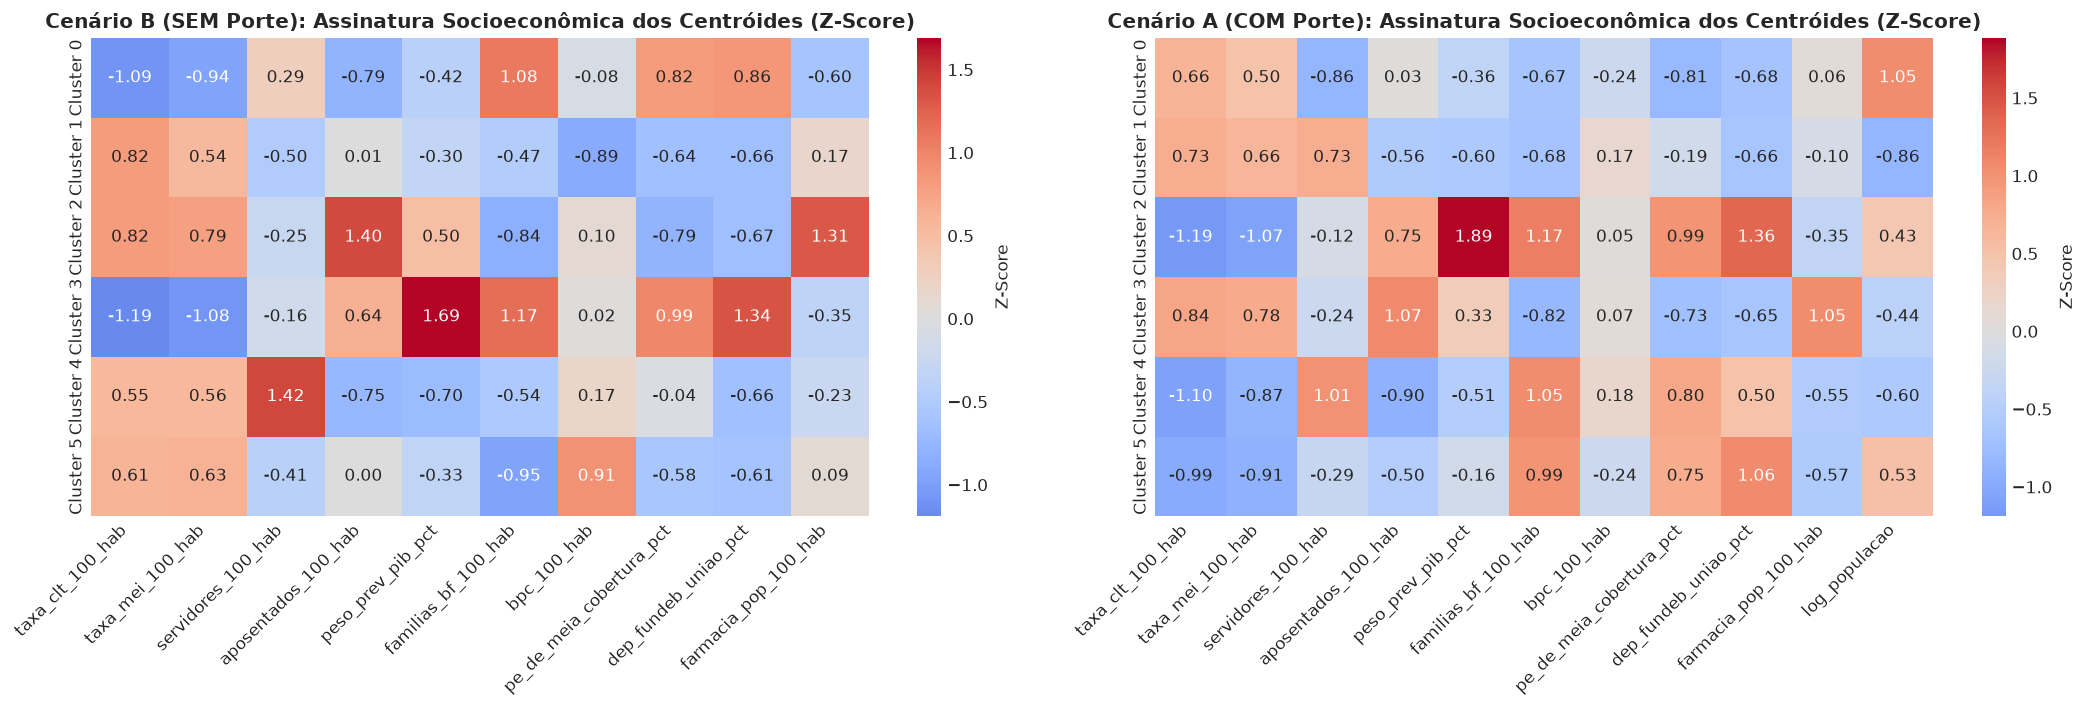

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

cols_sem = list(df_feat_sem_treino.columns)
df_heatmap_sem = pd.DataFrame(mean_sem_sc, columns=cols_sem)
df_heatmap_sem.index = [f"Cluster {i}" for i in range(len(df_heatmap_sem))]

sns.heatmap(df_heatmap_sem, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[0], cbar_kws={'label': 'Z-Score'})
axes[0].set_title('Cenário B (SEM Porte): Assinatura Socioeconômica dos Centróides (Z-Score)', fontsize=12, fontweight='bold')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')

cols_com = list(df_feat_com_treino.columns)
df_heatmap_com = pd.DataFrame(mean_com_sc, columns=cols_com)
df_heatmap_com.index = [f"Cluster {i}" for i in range(len(df_heatmap_com))]

sns.heatmap(df_heatmap_com, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1], cbar_kws={'label': 'Z-Score'})
axes[1].set_title('Cenário A (COM Porte): Assinatura Socioeconômica dos Centróides (Z-Score)', fontsize=12, fontweight='bold')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()


## 📊 7. Gráficos Comparativos de Dispersão
Visualizamos a distribuição das cidades nos planos fundamentais da estrutura socioeconômica brasileira:
1. **Força do Funcionalismo vs. Dependência de Transferência de Renda:** `servidores_100_hab` x `familias_bf_100_hab`.
2. **Mercado de Trabalho Formal vs. Dependência Previdenciária:** `taxa_clt_100_hab` x `aposentados_100_hab`.


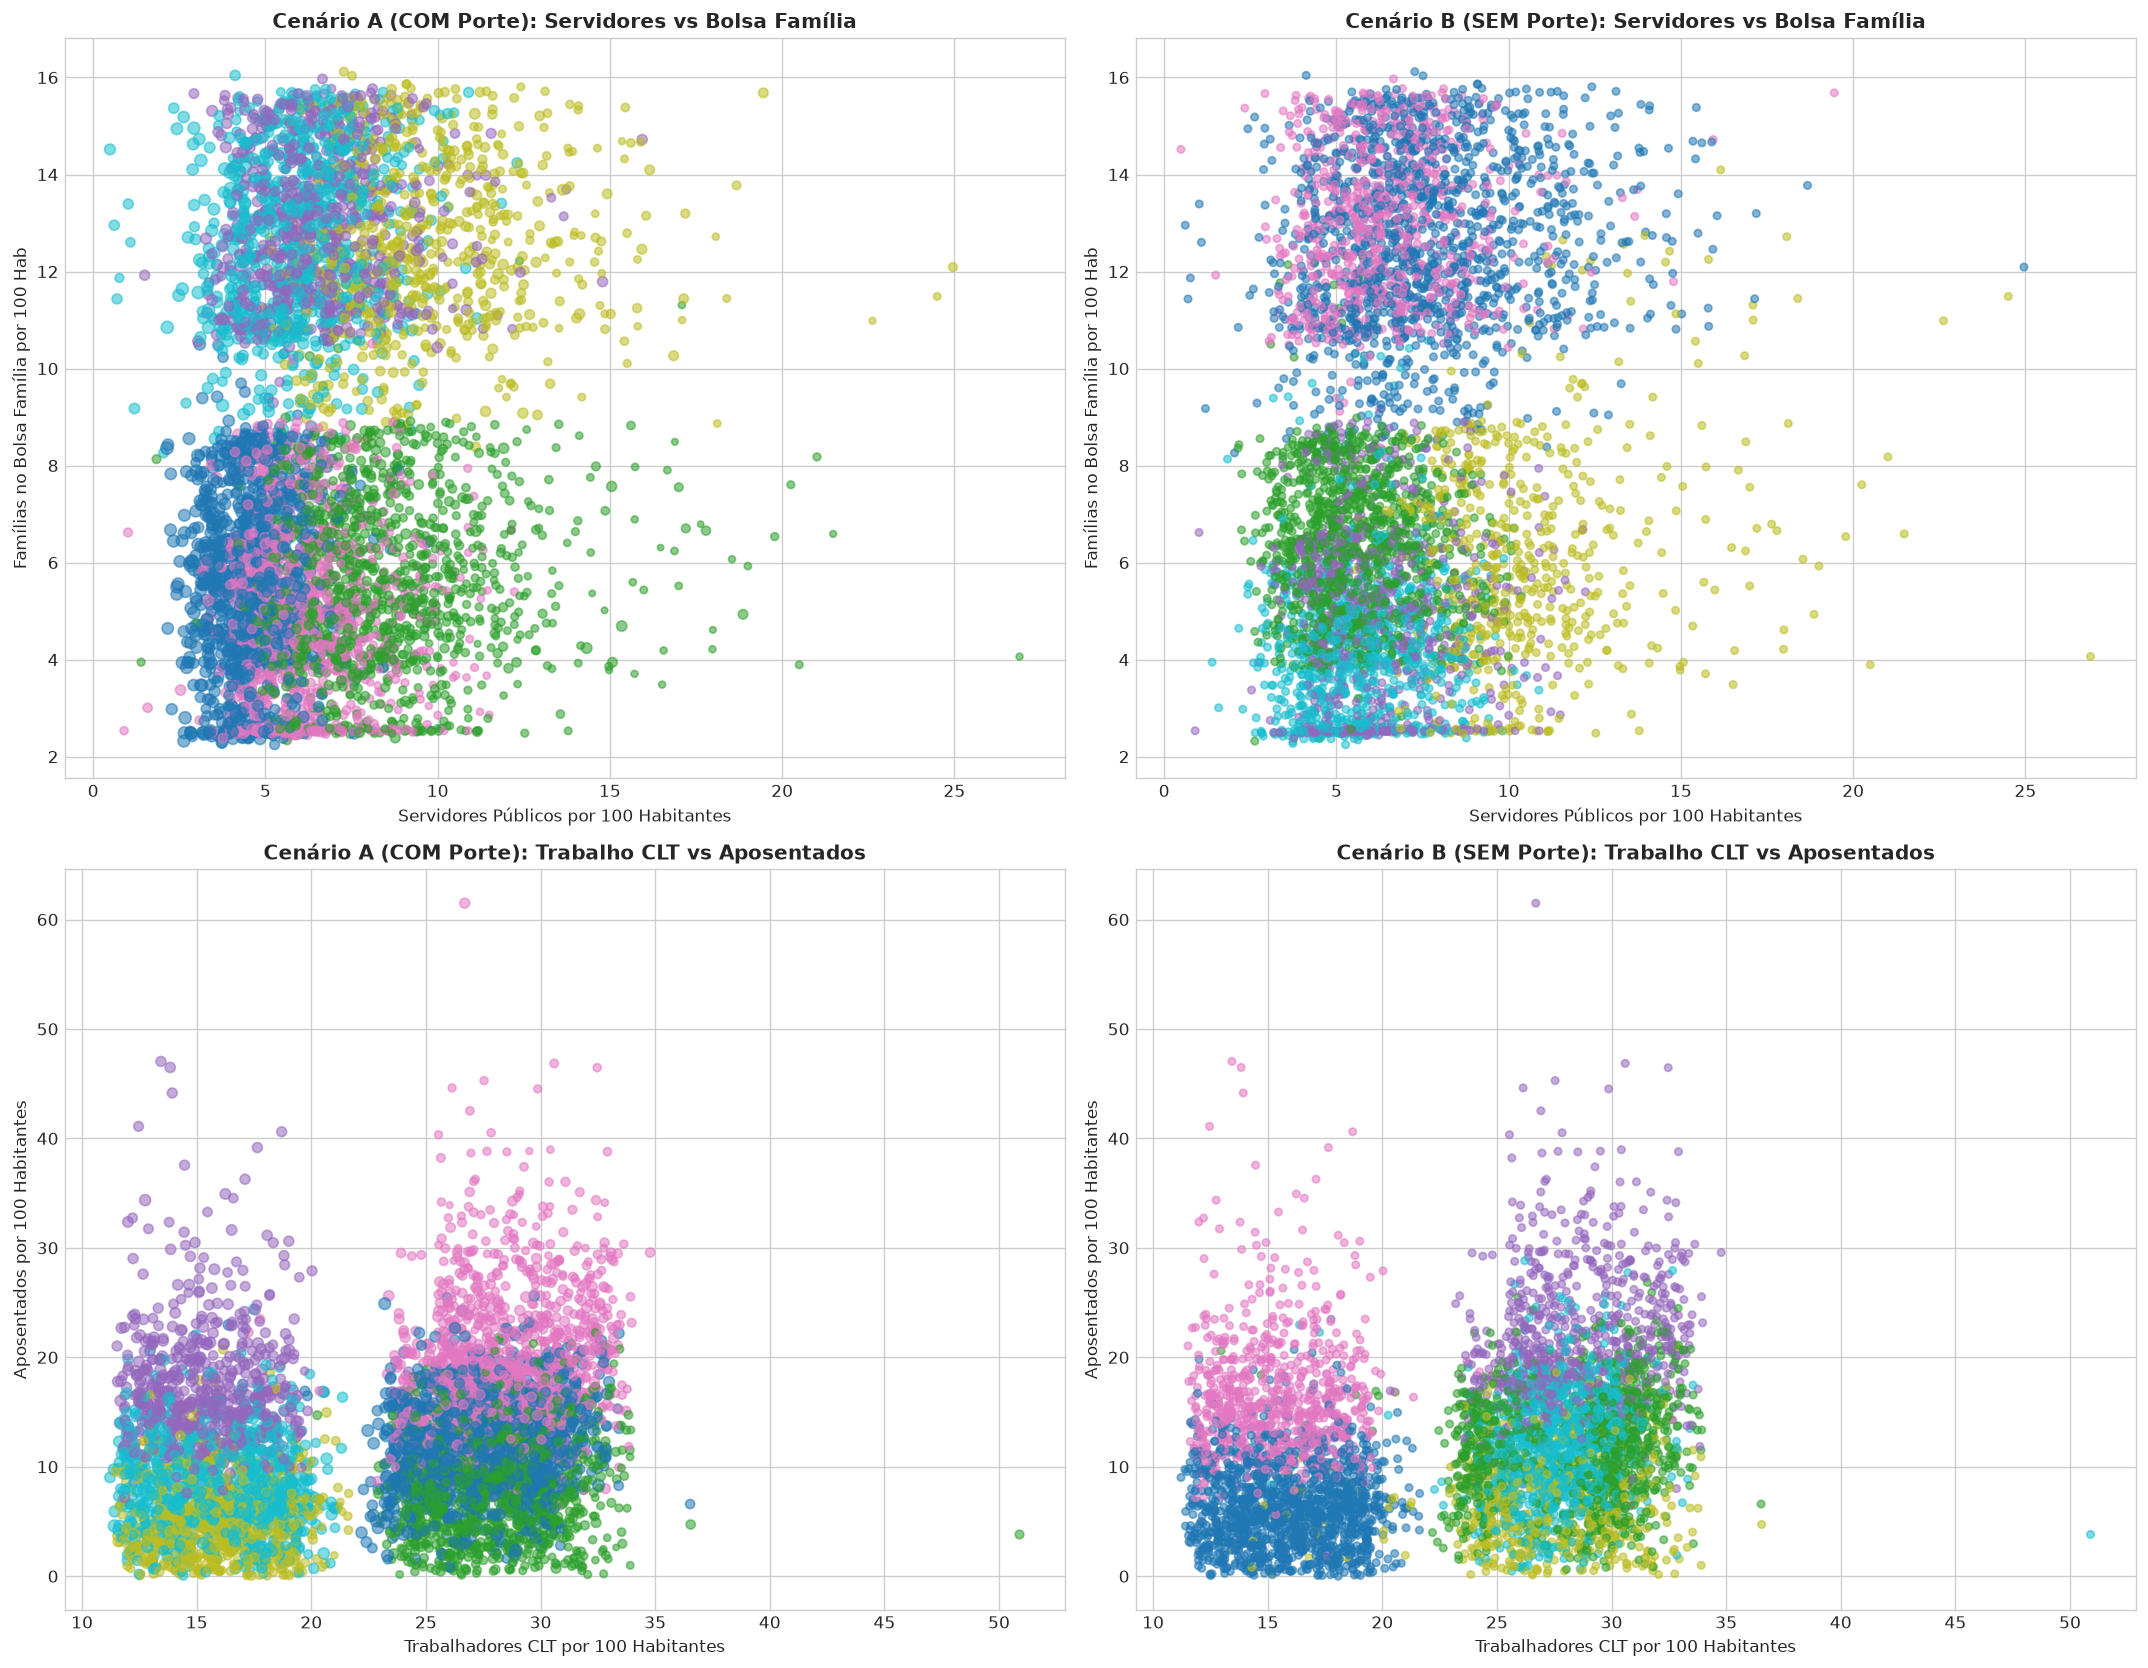

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# 1. Servidores vs Bolsa Família - Cenário A
axes[0, 0].scatter(
    df_feat_com_treino['servidores_100_hab'],
    df_feat_com_treino['familias_bf_100_hab'],
    c=labels_com, cmap='tab10', alpha=0.55, s=15 + (df_feat_com_treino['log_populacao'] - 3)*15
)
axes[0, 0].set_title('Cenário A (COM Porte): Servidores vs Bolsa Família', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Servidores Públicos por 100 Habitantes')
axes[0, 0].set_ylabel('Famílias no Bolsa Família por 100 Hab')

# 2. Servidores vs Bolsa Família - Cenário B
axes[0, 1].scatter(
    df_feat_sem_treino['servidores_100_hab'],
    df_feat_sem_treino['familias_bf_100_hab'],
    c=labels_sem, cmap='tab10', alpha=0.55, s=20
)
axes[0, 1].set_title('Cenário B (SEM Porte): Servidores vs Bolsa Família', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Servidores Públicos por 100 Habitantes')
axes[0, 1].set_ylabel('Famílias no Bolsa Família por 100 Hab')

# 3. CLT vs Aposentados - Cenário A
axes[1, 0].scatter(
    df_feat_com_treino['taxa_clt_100_hab'],
    df_feat_com_treino['aposentados_100_hab'],
    c=labels_com, cmap='tab10', alpha=0.55, s=15 + (df_feat_com_treino['log_populacao'] - 3)*15
)
axes[1, 0].set_title('Cenário A (COM Porte): Trabalho CLT vs Aposentados', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Trabalhadores CLT por 100 Habitantes')
axes[1, 0].set_ylabel('Aposentados por 100 Habitantes')

# 4. CLT vs Aposentados - Cenário B
axes[1, 1].scatter(
    df_feat_sem_treino['taxa_clt_100_hab'],
    df_feat_sem_treino['aposentados_100_hab'],
    c=labels_sem, cmap='tab10', alpha=0.55, s=20
)
axes[1, 1].set_title('Cenário B (SEM Porte): Trabalho CLT vs Aposentados', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Trabalhadores CLT por 100 Habitantes')
axes[1, 1].set_ylabel('Aposentados por 100 Habitantes')

plt.tight_layout()
plt.show()


## 🔍 8. Comparativo de Transição: Matriz de Cruzamento
Examinamos como as cidades se reorganizam entre o Cenário A (que pondera porte) e o Cenário B (intensidade pura).


In [9]:
tabela_contingencia = pd.crosstab(labels_com, labels_sem, rownames=['Cluster COM Porte'], colnames=['Cluster SEM Porte'])
print("📊 Matriz de Contingência (Cruzamento entre Cenário A e B):")
display(tabela_contingencia)


📊 Matriz de Contingência (Cruzamento entre Cenário A e B):


Cluster SEM Porte,0,1,2,3,4,5
Cluster COM Porte,,,,,,
0,2,650,36,0,5,393
1,1,280,3,0,532,315
2,0,1,0,615,0,0
3,0,180,683,0,0,237
4,656,0,0,12,36,1
5,739,2,0,139,0,0


## 🏷️ 9. Rotulação Semântica dos Perfis Socioeconômicos
Com base nos padrões estatísticos empíricos identificados pelo algoritmo de K-Means (Cenário B - SEM Porte), atribuímos nomes intuitivos e autoexplicativos a cada arquétipo:

* **Cluster 0: Jovens e Dependentes de Apoio Social** (1.398 cidades)
  * *Características:* Alta cobertura de programas sociais (Bolsa Família e Pé-de-Meia), alta dependência do Fundeb da União, perfil jovem e baixa taxa de emprego formal CLT.
* **Cluster 1: Polos Regionais de Emprego e Serviços** (1.113 cidades)
  * *Características:* Cidades médias do interior com mercado formal dinâmico (CLT e MEI elevados), baixa dependência de auxílios e baixa dependência federal.
* **Cluster 2: Cidades da Terceira Idade e Aposentados** (722 cidades)
  * *Características:* Fortíssima concentração de aposentados (22,1/100 hab), alto consumo de Farmácia Popular (15,1/100 hab), baixo Bolsa Família e bom dinamismo formal.
* **Cluster 3: Municípios Dependentes de Seguridade e Repasses** (766 cidades)
  * *Características:* Maior dependência de seguridade pública do país (17,6% do PIB em aposentadorias), alto Bolsa Família e máxima complementação do Fundeb.
* **Cluster 4: Pequenos Municípios do Funcionalismo Público** (573 cidades)
  * *Características:* Cidades de menor porte com máxima força do funcionalismo público (10,7 servidores por 100 hab — 1 em cada 10 habitantes trabalha no setor público).
* **Cluster 5: Cidades Autônomas e Agroindustriais** (946 cidades)
  * *Características:* Menor taxa de Bolsa Família do país (4,2/100 hab), forte emprego formal CLT e MEI, baixíssima dependência de repasses federais.
* **Grupo Âncora: Grandes Metrópoles e Capitais** (53 cidades)
  * *Características:* Cidades com população $\ge 500.000$ habitantes ou capitais de estado, isoladas previamente para preservar a escala dos clusters do interior.


In [10]:
nomes_perfis = {
    0: 'Jovens e Dependentes de Apoio Social',
    1: 'Polos Regionais de Emprego e Serviços',
    2: 'Cidades da Terceira Idade e Aposentados',
    3: 'Municípios Dependentes de Seguridade e Repasses',
    4: 'Pequenos Municípios do Funcionalismo Público',
    5: 'Cidades Autônomas e Agroindustriais'
}

descricoes_perfis = {
    0: 'Alta cobertura de programas sociais federais (Bolsa Família e Pé-de-Meia) e dependência do Fundeb, com população mais jovem.',
    1: 'Cidades médias do interior com mercado formal forte (CLT e MEI elevados), baixa dependência de auxílios e baixa dependência federal.',
    2: 'Fortíssima concentração de população aposentada (22,1/100 hab) e o maior consumo de medicamentos na Farmácia Popular, com boa atividade formal.',
    3: 'Maior dependência de seguridade e repasses do país: 17,6% do PIB em aposentadorias, alto Bolsa Família e máxima complementação do Fundeb.',
    4: 'Municípios de menor porte onde a força do funcionalismo público é máxima (10,7 servidores/100 hab — 1 em cada 10 hab trabalha no setor público).',
    5: 'Menor taxa de Bolsa Família do país (4,2/100 hab), forte emprego formal CLT e MEI, grande autonomia econômica e perfil agroindustrial/comercial.'
}

df_resultado = df_mun_treino.copy()
df_resultado['cluster_k6_com_porte'] = labels_com
df_resultado['cluster_k6_sem_porte'] = labels_sem
df_resultado['nome_perfil_socioeconomico'] = df_resultado['cluster_k6_sem_porte'].map(nomes_perfis)
df_resultado['descricao_perfil'] = df_resultado['cluster_k6_sem_porte'].map(descricoes_perfis)

# Tabela Resumo dos Perfis Renomeados
resumo_perfis = df_resultado.groupby('nome_perfil_socioeconomico').agg({
    'populacao_2025': ['count', 'mean', 'median']
}).round(0)
resumo_perfis.columns = ['Qtd_Municipios', 'Pop_Media', 'Pop_Mediana']
resumo_perfis = resumo_perfis.sort_values(by='Qtd_Municipios', ascending=False)

print("📊 Distribuição dos Municípios Brasileiros pelos Novos Perfis:")
display(resumo_perfis)


📊 Distribuição dos Municípios Brasileiros pelos Novos Perfis:


,Qtd_Municipios,Pop_Media,Pop_Mediana
nome_perfil_socioeconomico,,,
Jovens e Dependentes de Apoio Social,1398,25213.0,10932.0
Polos Regionais de Emprego e Serviços,1113,40249.0,14567.0
Cidades Autônomas e Agroindustriais,946,35527.0,12787.0
Municípios Dependentes de Seguridade e Repasses,766,26158.0,19142.0
Cidades da Terceira Idade e Aposentados,722,12139.0,7208.0
Pequenos Municípios do Funcionalismo Público,573,5378.0,3518.0


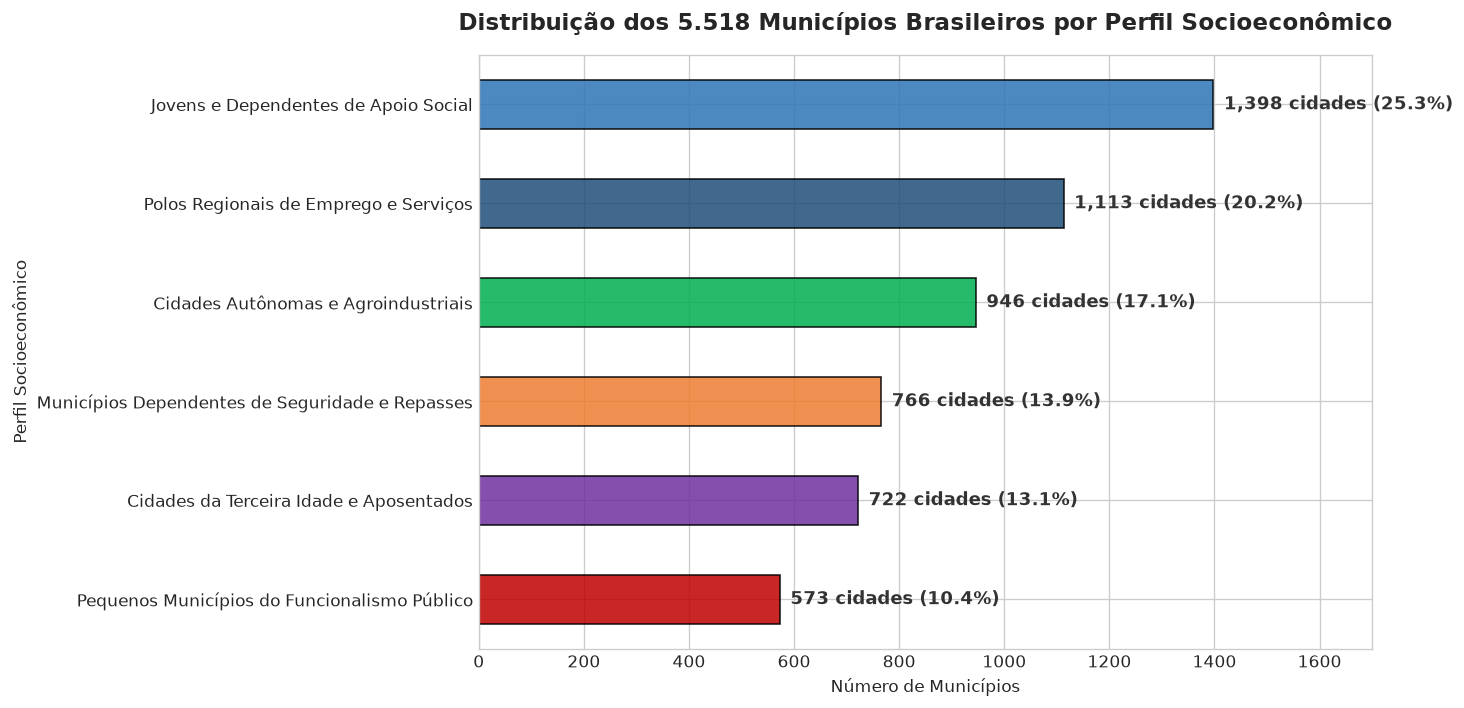

In [11]:
# Gráfico de barras horizontais: Quantidade de Cidades por Perfil
plt.figure(figsize=(12, 6))
cores_perfis = ['#2E75B6', '#1F4E79', '#00B050', '#ED7D31', '#7030A0', '#C00000']
ax = resumo_perfis['Qtd_Municipios'].plot(kind='barh', color=cores_perfis, edgecolor='black', alpha=0.85)

for p in ax.patches:
    ax.annotate(f"{int(p.get_width()):,} cidades ({p.get_width()/55.18:.1f}%)", 
                (p.get_width() + 20, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=11, fontweight='bold', color='#333333')

plt.title('Distribuição dos 5.518 Municípios Brasileiros por Perfil Socioeconômico', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Número de Municípios')
plt.ylabel('Perfil Socioeconômico')
plt.xlim(0, 1700)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## 💾 10. Exportação Completa das Bases de Dados e Planilhas
Salvamos a classificação final em dois formatos:
1. `dados_prioridades/clusters_com_e_sem_porte_municipios.csv`: Contendo as variáveis de intensidade e as duas classificações dos 5.518 municípios do interior.
2. `dados_prioridades/classificacao_perfis_municipios_completa.xlsx`: Base consolidada nacional cobrindo **100% dos 5.571 municípios** (os 5.518 municípios com seus respectivos clusters + as 53 Metrópoles e Capitais classificadas no seu grupo âncora).


In [12]:
# 1. Base dos 5.518 municípios com variáveis completas
df_export_interior = pd.concat([df_resultado, df_feat_com_treino], axis=1)
out_csv_interior = 'dados_prioridades/clusters_com_e_sem_porte_municipios.csv'
df_export_interior.to_csv(out_csv_interior, sep=';', index=False)
print(f"✅ Arquivo dos municípios do interior salvo: {out_csv_interior}")

# 2. Consolidação Nacional de TODOS os 5.571 Municípios Brasileiros
df_metr_export = df_metropoles_resumo.copy()
df_metr_export['cluster_k6_com_porte'] = -1
df_metr_export['cluster_k6_sem_porte'] = -1
df_metr_export['nome_perfil_socioeconomico'] = 'Grandes Metrópoles e Capitais'
df_metr_export['descricao_perfil'] = 'Grandes centros urbanos (população >= 500k ou capitais estaduais), analisadas em separado para preservar a escala dos clusters.'

cols_comuns = [c for c in df_export_interior.columns if c in df_metr_export.columns]
df_brasil_5571 = pd.concat([df_export_interior[cols_comuns], df_metr_export[cols_comuns]], ignore_index=True)
df_brasil_5571 = df_brasil_5571.sort_values(by='cod_ibge7').reset_index(drop=True)

out_xlsx_completo = 'dados_prioridades/classificacao_perfis_municipios_completa.xlsx'
out_csv_completo = 'dados_prioridades/classificacao_perfis_municipios_completa.csv'

with pd.ExcelWriter(out_xlsx_completo, engine='openpyxl') as writer:
    df_brasil_5571.to_excel(writer, sheet_name='Todos_Municipios_5571', index=False)
    
    # Aba Resumo comparando todos os perfis (incluindo metrópoles)
    resumo_nacional = df_brasil_5571.groupby('nome_perfil_socioeconomico').agg({
        'populacao_2025': ['count', 'mean'],
        'servidores_100_hab': 'mean',
        'taxa_clt_100_hab': 'mean',
        'taxa_mei_100_hab': 'mean',
        'aposentados_100_hab': 'mean',
        'peso_prev_pib_pct': 'mean',
        'familias_bf_100_hab': 'mean',
        'pe_de_meia_cobertura_pct': 'mean',
        'dep_fundeb_uniao_pct': 'mean',
        'farmacia_pop_100_hab': 'mean'
    }).round(1)
    resumo_nacional.to_excel(writer, sheet_name='Resumo_Perfis_Nacional')
    
    # Aba com Dicionário dos Perfis
    dic_perfis = pd.DataFrame([
        {'Perfil': nomes_perfis[k], 'Descricao': descricoes_perfis[k]} for k in nomes_perfis
    ] + [{'Perfil': 'Grandes Metrópoles e Capitais', 'Descricao': 'Grandes centros urbanos com mais de 500.000 habitantes ou capitais estaduais.'}])
    dic_perfis.to_excel(writer, sheet_name='Dicionario_Perfis', index=False)

df_brasil_5571.to_csv(out_csv_completo, sep=';', index=False)
print(f"🎉 Base completa dos 5.571 municípios exportada com sucesso:")
print(f" - {out_xlsx_completo}")
print(f" - {out_csv_completo}")


✅ Arquivo dos municípios do interior salvo: dados_prioridades/clusters_com_e_sem_porte_municipios.csv


🎉 Base completa dos 5.571 municípios exportada com sucesso:
 - dados_prioridades/classificacao_perfis_municipios_completa.xlsx
 - dados_prioridades/classificacao_perfis_municipios_completa.csv


## 🏙️ 11. Projeção e Reclassificação das 53 Metrópoles por Similaridade Socioeconômica
Nesta etapa, pegamos as **53 grandes metrópoles e capitais**, desconsideramos sua população absoluta (focando apenas nas intensidades per capita de CLT, MEI, servidores, Bolsa Família, previdência, etc.) e calculamos a distância euclidiana multivariada ($Z$-Score) de cada uma até os centróides dos clusters já estabelecidos.

* **Critério de Aderência:** Comparamos a distância com o limite do percentil 95 das cidades do interior ($Dist \le 3,02$).
  * **Se Sim ($Dist \le 3,02$):** A metrópole se comporta como o cluster e é **reclassificada** para aquele perfil socioeconômico.
  * **Se Não ($Dist > 3,02$):** A metrópole possui traços atípicos/extremos e **permanece classificada como Metrópole**.


In [13]:
# 1. Distâncias das cidades do interior aos seus centróides (usando a média das 30 simulações)
interior_dists = np.min(cdist(X_sem, mean_sem_sc), axis=1)
limiar_p95 = np.percentile(interior_dists, 95) # ~3.02

# 2. Projeção das 53 Metrópoles
X_metr = scaler_sem.transform(df_metropoles_resumo[cols_sem])
dist_metr = cdist(X_metr, mean_sem_sc)
nearest_cluster = np.argmin(dist_metr, axis=1)
dists_metr = np.min(dist_metr, axis=1)

df_metr_proj = df_metropoles_resumo.copy()
df_metr_proj['cluster_proximo_id'] = nearest_cluster
df_metr_proj['cluster_proximo_nome'] = df_metr_proj['cluster_proximo_id'].map(nomes_perfis)
df_metr_proj['distancia_centroide'] = dists_metr.round(2)
df_metr_proj['se_comporta_como_cluster'] = df_metr_proj['distancia_centroide'] <= limiar_p95
df_metr_proj['perfil_reclassificado'] = np.where(
    df_metr_proj['se_comporta_como_cluster'],
    df_metr_proj['cluster_proximo_nome'],
    'Grandes Metrópoles e Capitais (Atípicas)'
)

print(f"📊 Resultado da Aderência das 53 Metrópoles (Limiar P95 = {limiar_p95:.2f}):")
print(f" - Metrópoles que se comportam como os clusters: {df_metr_proj['se_comporta_como_cluster'].sum()} cidades")
print(f" - Metrópoles atípicas que permanecem isoladas: {(~df_metr_proj['se_comporta_como_cluster']).sum()} cidades")
print()

print("📋 TABELA COMPLETA DA RECLASSIFICAÇÃO DAS 53 METRÓPOLES:")
display(df_metr_proj[['municipio', 'uf', 'populacao_2025', 'cluster_proximo_nome', 'distancia_centroide', 'perfil_reclassificado']].sort_values(by='distancia_centroide'))


📊 Resultado da Aderência das 53 Metrópoles (Limiar P95 = 3.02):
 - Metrópoles que se comportam como os clusters: 48 cidades
 - Metrópoles atípicas que permanecem isoladas: 5 cidades

📋 TABELA COMPLETA DA RECLASSIFICAÇÃO DAS 53 METRÓPOLES:


,municipio,uf,populacao_2025,cluster_proximo_nome,distancia_centroide,perfil_reclassificado
3824,São José dos Campos,SP,727078,Polos Regionais de Emprego e Serviços,1.21,Polos Regionais de Emprego e Serviços
5122,Campo Grande,MS,962883,Cidades Autônomas e Agroindustriais,1.24,Cidades Autônomas e Agroindustriais
4102,Londrina,PR,581382,Polos Regionais de Emprego e Serviços,1.34,Polos Regionais de Emprego e Serviços
3173,Vila Velha,ES,506779,Polos Regionais de Emprego e Serviços,1.39,Polos Regionais de Emprego e Serviços
2309,Belo Horizonte,MG,2415872,Polos Regionais de Emprego e Serviços,1.40,Polos Regionais de Emprego e Serviços
5570,Brasília,DF,2996899,Cidades Autônomas e Agroindustriais,1.43,Cidades Autônomas e Agroindustriais
3067,Uberlândia,MG,761835,Cidades Autônomas e Agroindustriais,1.43,Cidades Autônomas e Agroindustriais
3479,Guarulhos,SP,1349100,Polos Regionais de Emprego e Serviços,1.44,Polos Regionais de Emprego e Serviços
3848,Sorocaba,SP,762172,Cidades Autônomas e Agroindustriais,1.48,Cidades Autônomas e Agroindustriais
3222,Niterói,RJ,516787,Cidades Autônomas e Agroindustriais,1.49,Cidades Autônomas e Agroindustriais


In [14]:
# Incorporação da Reclassificação na Base Consolidada de 5.571 Municípios
dict_reclass_metr = dict(zip(df_metr_proj['cod_ibge7'], df_metr_proj['perfil_reclassificado']))

df_brasil_5571['perfil_final_reclassificado'] = df_brasil_5571['cod_ibge7'].map(dict_reclass_metr).fillna(df_brasil_5571['nome_perfil_socioeconomico'])

# Resumo Final Nacional após a Reclassificação
resumo_final_reclass = df_brasil_5571.groupby('perfil_final_reclassificado').agg({
    'cod_ibge7': 'count',
    'populacao_2025': ['sum', 'mean'],
    'servidores_100_hab': 'mean',
    'taxa_clt_100_hab': 'mean',
    'taxa_mei_100_hab': 'mean',
    'familias_bf_100_hab': 'mean'
}).round(1)

print("📋 DISTRIBUIÇÃO NACIONAL FINAL (COM METRÓPOLES RECLASSIFICADAS):")
display(resumo_final_reclass)

# Atualização da Planilha Excel com a base completa atualizada e as novas abas
with pd.ExcelWriter(out_xlsx_completo, engine='openpyxl', mode='a', if_sheet_exists='replace') as writer:
    df_brasil_5571.to_excel(writer, sheet_name='Todos_Municipios_5571', index=False)
    df_metr_proj[['cod_ibge7', 'municipio', 'uf', 'populacao_2025', 'cluster_proximo_nome', 'distancia_centroide', 'perfil_reclassificado']].to_excel(writer, sheet_name='Metropoles_Reclassificadas', index=False)
    resumo_final_reclass.to_excel(writer, sheet_name='Resumo_Pos_Reclassificacao')

df_brasil_5571.to_csv(out_csv_completo, sep=';', index=False)
print("✅ Base consolidada e planilha Excel atualizadas com a nova classificação!")


📋 DISTRIBUIÇÃO NACIONAL FINAL (COM METRÓPOLES RECLASSIFICADAS):


cod_ibge7 populacao_2025  \
                                                    count            sum   
perfil_final_reclassificado                                                
Cidades Autônomas e Agroindustriais                   957       54165268   
Cidades da Terceira Idade e Aposentados               722        8764244   
Grandes Metrópoles e Capitais (Atípicas)                5        3600579   
Jovens e Dependentes de Apoio Social                 1414       53338433   
Municípios Dependentes de Seguridade e Repasses       766       20036681   
Pequenos Municípios do Funcionalismo Público          573        3081453   
Polos Regionais de Emprego e Serviços                1134       70434379   

                                                          servidores_100_hab  \
                                                     mean               mean   
perfil_final_reclassificado                                                    
Cidades Autônomas e Agroindustriais               56599.0                5.6   
Cidades da Terceira Idade e Aposentados           12138.8                6.2   
Grandes Metrópoles e Capitais (Atípicas)         720115.8                2.8   
Jovens e Dependentes de Apoio Social              37721.7                7.6   
Municípios Dependentes de Seguridade e Repasses   26157.5                6.4   
Pequenos Municípios do Funcionalismo Público       5377.8               10.7   
Polos Regionais de Emprego e Serviços             62111.4                5.5   

                                                taxa_clt_100_hab  \
                                                            mean   
perfil_final_reclassificado                                        
Cidades Autônomas e Agroindustriais                         27.3   
Cidades da Terceira Idade e Aposentados                     28.5   
Grandes Metrópoles e Capitais (Atípicas)                    18.4   
Jovens e Dependentes de Apoio Social                        16.0   
Municípios Dependentes de Seguridade e Repasses             15.4   
Pequenos Municípios do Funcionalismo Público                26.9   
Polos Regionais de Emprego e Serviços                       28.4   

                                                taxa_mei_100_hab  \
                                                            mean   
perfil_final_reclassificado                                        
Cidades Autônomas e Agroindustriais                          9.3   
Cidades da Terceira Idade e Aposentados                      9.6   
Grandes Metrópoles e Capitais (Atípicas)                     5.4   
Jovens e Dependentes de Apoio Social                         6.0   
Municípios Dependentes de Seguridade e Repasses              5.7   
Pequenos Municípios do Funcionalismo Público                 9.1   
Polos Regionais de Emprego e Serviços                        9.0   

                                                familias_bf_100_hab  
                                                               mean  
perfil_final_reclassificado                                          
Cidades Autônomas e Agroindustriais                             4.2  
Cidades da Terceira Idade e Aposentados                         5.0  
Grandes Metrópoles e Capitais (Atípicas)                       12.3  
Jovens e Dependentes de Apoio Social                           12.6  
Municípios Dependentes de Seguridade e Repasses                13.0  
Pequenos Municípios do Funcionalismo Público                    6.2  
Polos Regionais de Emprego e Serviços                           6.5

✅ Base consolidada e planilha Excel atualizadas com a nova classificação!
